# Does the rule produce spatial mixing that settles?

Notebook 1 summarized same-group neighbor percentages. Here we use final locations to calculate three established PySAL segregation measures and read them alongside settling.

## 1. What we measure
Each neighborhood includes a patch and its up to eight surrounding patches, without wrapping. Neighborhoods overlap. Use the same definition in every run.

- **Isolation:** how much the focal group encounters its own group locally.
- **CorrelationR:** isolation adjusted for the group's proportion in the populations compared.
- **Dissim:** how unevenly the two groups are distributed across local neighborhoods.

Higher values indicate greater separation in the relevant measure. The scores have different baselines; they are not percentages of people segregated. We compare settings without imposing a universal cutoff.

[PySAL documentation](https://pysal.org/segregation/api.html)

## 2. Load the experiment
The run number and final tick identify each matching position file on GitHub.

In [ ]:
%pip -q install segregation==2.6.0 geopandas

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from libpysal.weights import lat2W
from segregation.singlegroup import Isolation, CorrelationR, Dissim

BASE_URL = 'https://raw.githubusercontent.com/DACSS-Complexity/s6_From_Micromotives_to_Macrobehavior/main/exercise/'
run_summary = pd.read_csv(BASE_URL + 'policy-relocation-table.csv', skiprows=6).rename(columns={
    '[run number]': 'run', '%-similar-required': 'minimum',
    'all? citizens [requirement-met?]': 'settled'})

## 3. Define the grid and neighbors
Represent all patches, including vacancies. Coordinates are simulation locations, not an Earth location. `lat2W(..., rook=False)` defines eight-neighbor adjacency; PySAL includes the focal patch in its local counts.

In [2]:
coordinates = pd.MultiIndex.from_product(
    [range(-25, 26), range(-25, 26)], names=['y', 'x']).to_frame(index=False)
local_crs = 'LOCAL_CS["NetLogo grid",LOCAL_DATUM["Simulation",0],UNIT["patch",1],AXIS["x",EAST],AXIS["y",NORTH]]'
grid = gpd.GeoDataFrame(coordinates,
    geometry=gpd.points_from_xy(coordinates.x, coordinates.y), crs=local_crs)
w = lat2W(51, 51, rook=False)

## 4. Calculate segregation for each run
Join positions to the grid. `total` counts occupancy; `focal` counts group 0. Apply the same three indices to every endpoint and retain whether the run settled.

In [3]:
records = []
benchmark_positions = {}
for r in run_summary.sort_values('run').itertuples():
    filename = f'positions-run-{int(r.run)}-tick-{int(r.ticks)}.csv'
    positions = pd.read_csv(BASE_URL + filename)
    if r.minimum in [10, 30]:
        benchmark_positions[int(r.run)] = positions
    g = grid.merge(positions[['x', 'y', 'group']], on=['x', 'y'], how='left', sort=False)
    g['total'] = g.group.notna().astype(int)
    g['focal'] = g.group.eq(0).astype(int)
    records.append(dict(run=r.run, minimum=r.minimum, settled=r.settled,
        isolation=Isolation(g, 'focal', 'total', w=w).statistic,
        correlation_ratio=CorrelationR(g, 'focal', 'total', w=w).statistic,
        dissimilarity=Dissim(g, 'focal', 'total', w=w).statistic))
spatial = pd.DataFrame(records)

## 5. Compare the rules
Average each index across the 30 repetitions. Report settling separately: a low segregation score at the cap is not settled mixing.

In [4]:
summary = spatial.groupby('minimum').agg(
    isolation=('isolation', 'mean'),
    correlation_ratio=('correlation_ratio', 'mean'),
    dissimilarity=('dissimilarity', 'mean'),
    settled_runs=('settled', 'sum'))
summary.round(3)

,isolation,correlation_ratio,dissimilarity,settled_runs
minimum,,,,
10,0.578,0.151,0.307,30
15,0.599,0.196,0.348,30
20,0.614,0.229,0.377,30
25,0.620,0.247,0.395,30
30,0.723,0.447,0.576,30
35,0.753,0.507,0.626,30
40,0.784,0.570,0.679,30
45,0.839,0.678,0.763,30
50,0.838,0.675,0.761,30


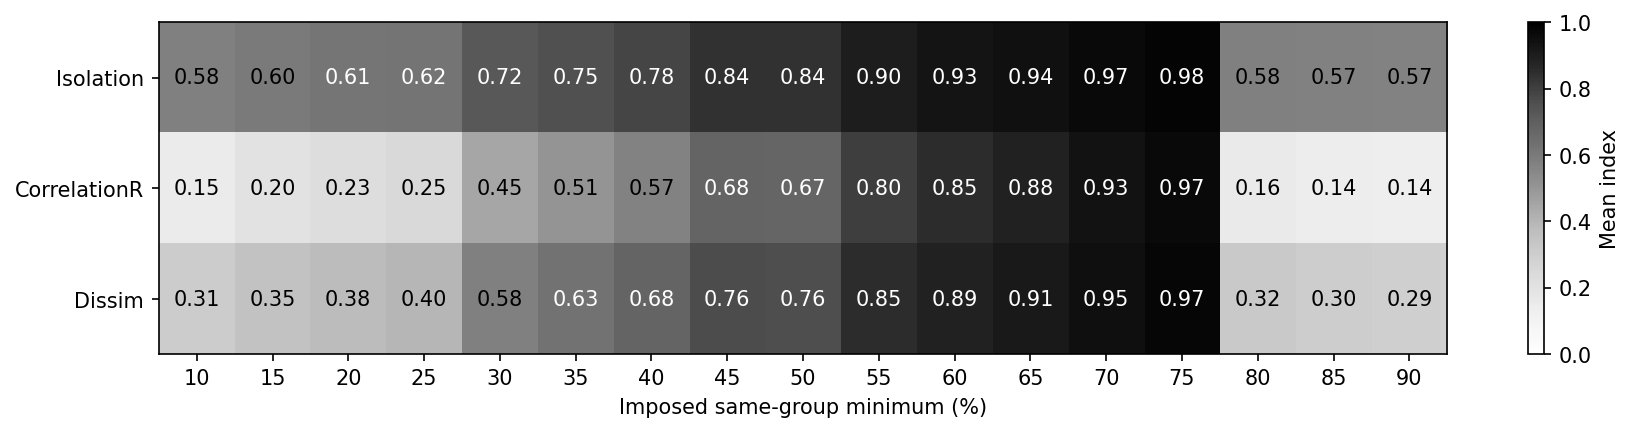

In [5]:
values = summary[['isolation', 'correlation_ratio', 'dissimilarity']].T
fig, ax = plt.subplots(figsize=(12, 3))
heatmap = ax.imshow(values, vmin=0, vmax=1, cmap='Greys', aspect='auto')
ax.set_xticks(range(len(values.columns)), values.columns)
ax.set_yticks(range(3), ['Isolation', 'CorrelationR', 'Dissim'])
ax.set_xlabel('Imposed same-group minimum (%)')
for row in range(3):
    for column in range(len(values.columns)):
        value = values.iloc[row, column]
        ax.text(column, row, f'{value:.2f}', ha='center', va='center',
                color='white' if value > 0.6 else 'black')
fig.colorbar(heatmap, ax=ax, label='Mean index')
fig.tight_layout()
plt.show()

## 6. Is the separation greater than random mixing?
A score need not be zero under random mixing. To interpret the proposed **30% rule**, construct a reference city from each endpoint:

1. Keep the occupied locations, vacancies, and number of citizens in each group unchanged.
2. Shuffle group labels among occupied locations **999 times**.
3. Recalculate the same three measures with the same neighborhoods.
4. Compare the observed score with the **95th percentile** of its shuffled scores.

Above that percentile means **more separation than random mixing would ordinarily produce**, under this specified benchmark. It is not a universal policy threshold. We test all 30 repetitions at 30%, and include all 30 at 10% for comparison.

The shuffling happens **before** counting neighborhoods. Otherwise we would not preserve the correct relationship between people and locations. The calculations below evaluate the same index formulas in arrays to avoid fitting thousands of duplicate objects; observed and shuffled examples were checked against PySAL 2.6.0. These are not new indices.

In [ ]:
import numpy as np

# The same neighborhoods used by PySAL, including the focal patch.
neighborhoods = w.sparse.copy()
neighborhoods.setdiag(1)
metrics = ['isolation', 'correlation_ratio', 'dissimilarity']
benchmark_records = []

for run, positions in sorted(benchmark_positions.items()):
    minimum = positions.minimum.iloc[0]
    locations = ((positions.y + 25) * 51 + positions.x + 25).to_numpy(dtype=int)
    group0 = positions.group.eq(0).to_numpy(dtype=float)
    occupied = np.zeros(len(grid))
    occupied[locations] = 1
    total = (neighborhoods @ occupied)[:, None]
    rng = np.random.default_rng(20261026 + run)
    labels = np.column_stack([group0] + [rng.permutation(group0) for _ in range(999)])
    population = np.zeros((len(grid), 1000))
    population[locations] = labels
    local = neighborhoods @ population

    # Each column is one arrangement: observed first, then 999 shuffles.
    X = local.sum(axis=0)
    T = total.sum()
    P = X / T
    share = np.divide(local, total, out=np.zeros_like(local), where=total != 0)
    isolation = (local * share).sum(axis=0) / X
    correlation_ratio = (isolation - P) / (1 - P)
    dissimilarity = (total * abs(share - P)).sum(axis=0) / (2 * T * P * (1 - P))

    for metric, values in zip(metrics, [isolation, correlation_ratio, dissimilarity]):
        observed, shuffled = values[0], values[1:]
        cutoff = np.quantile(shuffled, 0.95)
        benchmark_records.append(dict(run=run, minimum=minimum, metric=metric,
            observed=observed, random_mean=shuffled.mean(), random_95th=cutoff,
            above_95th=observed > cutoff,
            p_one_sided=(1 + (shuffled >= observed).sum()) / 1000))

benchmark = pd.DataFrame(benchmark_records)


In [ ]:
benchmark_summary = benchmark.groupby(['minimum', 'metric']).agg(
    observed_mean=('observed', 'mean'),
    random_mean=('random_mean', 'mean'),
    runs_above_benchmark=('above_95th', 'sum'))
benchmark_summary.round(3)

observed_mean  random_mean  runs_above_benchmark
minimum metric                                                             
10      correlation_ratio          0.151        0.134                    24
        dissimilarity              0.307        0.293                    16
        isolation                  0.578        0.569                    24
30      correlation_ratio          0.447        0.134                    30
        dissimilarity              0.576        0.293                    30
        isolation                  0.723        0.567                    30

### How to read the benchmark
Each run has its **own** reference distribution and cutoff. The table averages scores across runs but counts comparisons made within runs. `runs_above_benchmark` is therefore the number of repetitions above their own random-mixing 95th percentile, not above one pooled cutoff.

The optional `p_one_sided` records the fraction of shuffled scores at least as large as the observed score, using the observed arrangement in the denominator. With 999 shuffles, the smallest reported value is 0.001. The comparisons are per run and measure, without a multiple-testing adjustment; the three measures are related.

## 7. Policy answer
**Do not adopt the proposed 30% minimum as a way to prevent residential segregation.** The spatial analysis reinforces Notebook 1: all 30 runs settle, but all three measures show separation beyond their random-mixing benchmarks in every run.

| Measure | Observed mean at 30% | Random-mixing mean | Runs above their benchmark |
|---|---:|---:|---:|
| Isolation | **0.723** | 0.567 | **30/30** |
| CorrelationR | **0.447** | 0.134 | **30/30** |
| Dissim | **0.576** | 0.293 | **30/30** |

The rule misses its mixing goal because residents experience more same-group concentration than random assignment would ordinarily produce; that isolation persists after composition adjustment; and the two groups occupy local environments unevenly. In each corresponding test, the observed value exceeds all 999 shuffled values. Compliance therefore does not establish integration.

**Instead, replace the proposed 30% minimum with a 10% minimum.** It is the **best-supported option among those tested**: every run settles, same-group similarity averages **51.3%**, and all three spatial segregation measures are lower.

| Measure | 30% minimum | Recommended 10% minimum |
|---|---:|---:|
| Isolation | 0.723 | **0.578** |
| CorrelationR | 0.447 | **0.151** |
| Dissim | 0.576 | **0.307** |

The recommendation is to reduce segregation, not promise its elimination. At 10%, scores still exceed the random benchmark in 24/30 runs for Isolation and CorrelationR and 16/30 for Dissim. The model supports choosing 10% over the proposed 30% for the residential objective; it does not establish that this choice is uniquely feasible or that it reduces revolt risk.